# 01 — Analyse exploratoire des données

**Jeu de données :** HMEQ (*Home Equity Loans*) — 5 960 demandes de prêt garanti par un bien immobilier, avec l'issue du prêt (`BAD` = 1 si le client a fait défaut).

**Règle suivie :** toute l'exploration porte sur le **jeu de développement** (80 % des demandes). Le jeu de test n'est jamais ouvert ici : ce que l'on observe guide nos choix de prétraitement, et ces choix ne doivent pas être influencés par les données de l'évaluation finale.

Prérequis : `python -m src.download_data` puis `python -m src.split_data`.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

from src.config import CAT_COLS, DEV_FILE, FIG_DIR, LABELS, NUM_COLS, RAW_COLS, TARGET
from src.plots import C_BAD, C_GOOD, GREY, set_style

set_style()
dev = pd.read_csv(DEV_FILE)[[TARGET] + RAW_COLS]
good, bad = dev[dev[TARGET] == 0], dev[dev[TARGET] == 1]
print(f"{len(dev)} demandes, {len(RAW_COLS)} variables explicatives")
dev.head()

4768 demandes, 12 variables explicatives


,BAD,LOAN,MORTDUE,VALUE,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,REASON,JOB
0,0,7700,70451.00,81862.0,3.0,0.0,0.0,141.268671,0.0,31.0,31.681943,DebtCon,Sales
1,1,21000,48735.00,71694.0,8.0,0.0,0.0,48.498971,3.0,10.0,32.921401,DebtCon,Other
2,0,11500,63136.00,81099.0,3.0,NaN,NaN,149.064745,NaN,35.0,28.975940,DebtCon,Other
3,0,9900,55342.00,72357.0,7.0,NaN,3.0,111.998855,1.0,11.0,39.870340,DebtCon,Mgr
4,0,9000,47350.86,105000.0,6.0,0.0,1.0,227.266667,0.0,10.0,NaN,DebtCon,ProfExe


## 1. Dictionnaire des variables et vue d'ensemble

In [2]:
overview = pd.DataFrame({
    "signification": pd.Series(LABELS).reindex(RAW_COLS),
    "type": dev[RAW_COLS].dtypes.astype(str),
    "manquants (%)": (100 * dev[RAW_COLS].isna().mean()).round(1),
    "valeurs uniques": dev[RAW_COLS].nunique(),
})
display(overview)
display(dev[NUM_COLS].describe().T.round(1))
print("Demandes complètes (aucune valeur manquante) :", f"{dev[RAW_COLS].notna().all(axis=1).mean():.1%}")

,signification,type,manquants (%),valeurs uniques
LOAN,Montant du prêt demandé,int64,0.0,512
MORTDUE,Capital restant dû sur l'hypothèque,float64,8.8,4064
VALUE,Valeur actuelle du bien,float64,1.9,4340
YOJ,Ancienneté dans l'emploi (années),float64,8.5,90
DEROG,Incidents de paiement majeurs,float64,12.3,11
DELINQ,Lignes de crédit en retard de paiement,float64,9.9,14
CLAGE,Âge de la plus ancienne ligne de crédit (mois),float64,5.4,4278
NINQ,Demandes de crédit récentes,float64,8.7,15
CLNO,Nombre de lignes de crédit,float64,3.9,62
DEBTINC,Ratio dette / revenu (%),float64,21.1,3763


,count,mean,std,min,25%,50%,75%,max
LOAN,4768.0,18531.9,11230.9,1100.0,11000.0,16200.0,23300.0,89900.0
MORTDUE,4347.0,73678.8,44250.8,2063.0,46122.0,65022.0,91731.5,399550.0
VALUE,4679.0,101640.0,56972.6,8000.0,66192.5,89250.0,119780.0,855909.0
YOJ,4365.0,8.9,7.6,0.0,3.0,7.0,13.0,41.0
DEROG,4180.0,0.3,0.8,0.0,0.0,0.0,0.0,10.0
DELINQ,4296.0,0.5,1.1,0.0,0.0,0.0,0.0,15.0
CLAGE,4509.0,179.5,86.2,0.0,115.6,173.5,230.1,1168.2
NINQ,4354.0,1.2,1.7,0.0,0.0,1.0,2.0,17.0
CLNO,4584.0,21.3,10.2,0.0,14.0,20.0,26.0,71.0
DEBTINC,3763.0,33.8,8.3,0.5,29.2,34.8,39.0,203.3


Demandes complètes (aucune valeur manquante) : 56.4%


## 2. Le déséquilibre des classes

Défauts : 951  |  Remboursés : 3817  |  Taux de défaut : 19.9%  |  1 défaut pour 4.0 bons payeurs
Un modèle qui répond toujours « remboursera » a une exactitude de 80.1% et ne détecte aucun défaut.


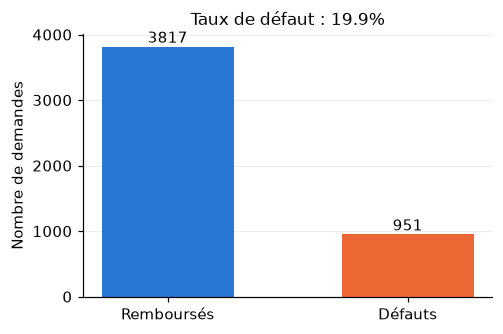

In [3]:
n_b, n_g = len(bad), len(good)
print(f"Défauts : {n_b}  |  Remboursés : {n_g}  |  Taux de défaut : {n_b / len(dev):.1%}  |  1 défaut pour {n_g / n_b:.1f} bons payeurs")
print(f"Un modèle qui répond toujours « remboursera » a une exactitude de {n_g / len(dev):.1%} et ne détecte aucun défaut.")
fig, ax = plt.subplots(figsize=(4.8, 3.1))
bars = ax.bar(["Remboursés", "Défauts"], [n_g, n_b], color=[C_GOOD, C_BAD], width=0.55)
for b, v in zip(bars, [n_g, n_b]):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v}", ha="center")
ax.set_ylabel("Nombre de demandes"); ax.set_title(f"Taux de défaut : {n_b / len(dev):.1%}"); ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "eda_desequilibre.png"); plt.show()

## 3. Les valeurs manquantes sont-elles informatives ?

On compare le taux de défaut selon que la variable est renseignée ou non.

,manquants (%),taux de défaut si manquant (%),taux de défaut si renseigné (%)
variable,,,
VALUE,1.9,93.3,18.6
DEBTINC,21.1,61.9,8.7
CLAGE,5.4,25.9,19.6
CLNO,3.9,25.0,19.7
MORTDUE,8.8,20.0,19.9
REASON,4.1,17.9,20.0
NINQ,8.7,15.5,20.4
DELINQ,9.9,13.1,20.7
YOJ,8.5,12.9,20.6


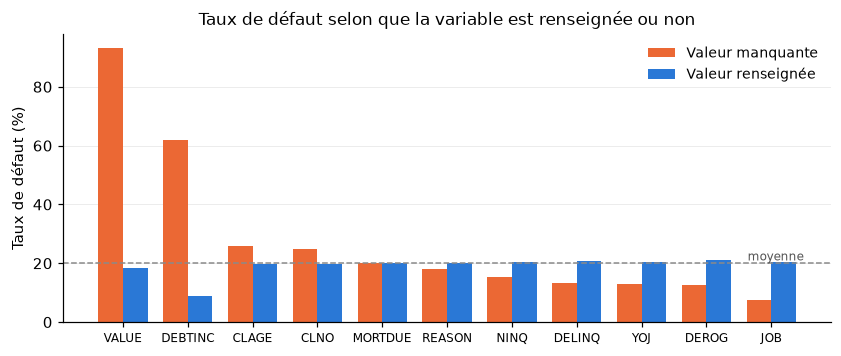

In [4]:
rows = []
for c in RAW_COLS:
    m = dev[c].isna()
    if m.any():
        rows.append({"variable": c, "manquants (%)": 100 * m.mean(),
                     "taux de défaut si manquant (%)": 100 * dev.loc[m, TARGET].mean(),
                     "taux de défaut si renseigné (%)": 100 * dev.loc[~m, TARGET].mean()})
miss = pd.DataFrame(rows).set_index("variable").sort_values("taux de défaut si manquant (%)", ascending=False)
display(miss.round(1))
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(miss)); w = 0.38
ax.bar(x - w / 2, miss["taux de défaut si manquant (%)"], w, color=C_BAD, label="Valeur manquante")
ax.bar(x + w / 2, miss["taux de défaut si renseigné (%)"], w, color=C_GOOD, label="Valeur renseignée")
ax.axhline(100 * dev[TARGET].mean(), color=GREY, ls="--", lw=1); ax.text(len(miss) - 0.5, 100 * dev[TARGET].mean() + 1, "moyenne", ha="right", fontsize=8, color="#555")
ax.set_xticks(x); ax.set_xticklabels(miss.index, fontsize=8); ax.set_ylabel("Taux de défaut (%)")
ax.set_title("Taux de défaut selon que la variable est renseignée ou non"); ax.legend(); ax.grid(axis="x", visible=False)
fig.savefig(FIG_DIR / "eda_manquants.png"); plt.show()

## 4. Variables numériques : défauts contre remboursés

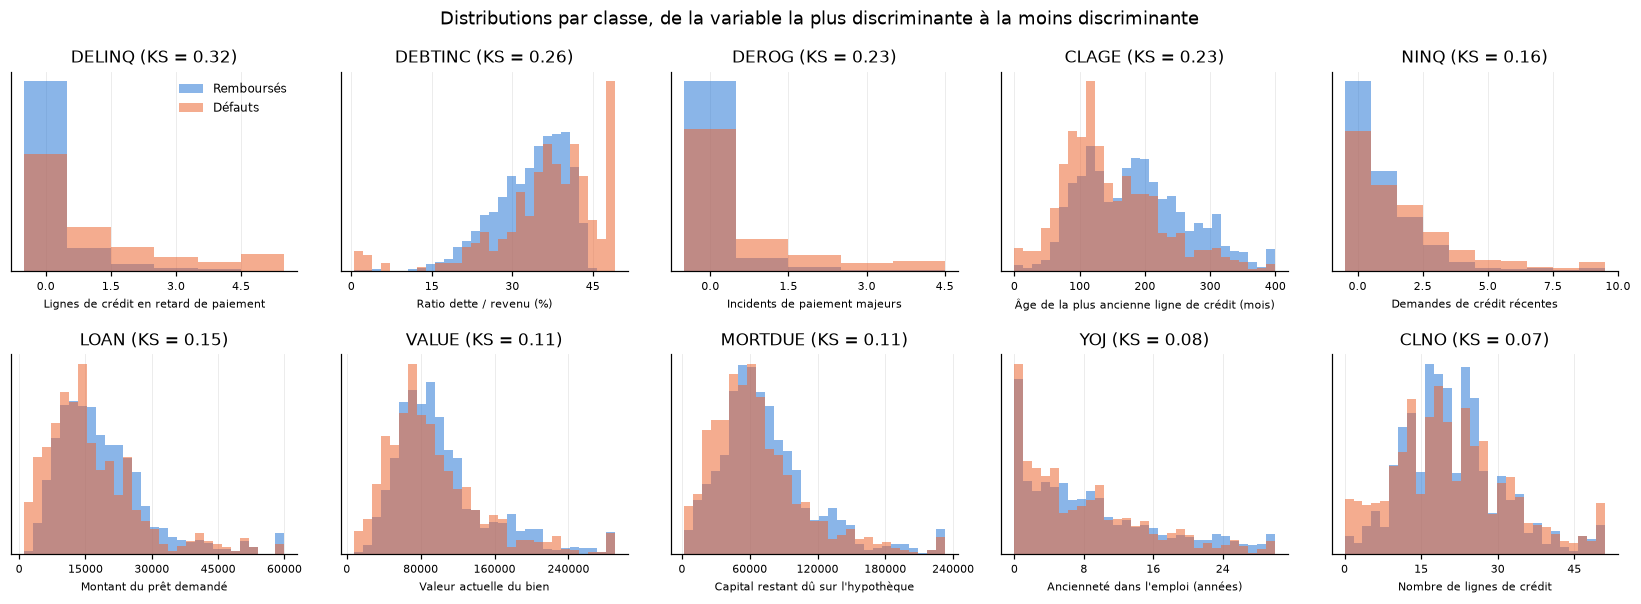

,médiane remboursés,médiane défauts,moyenne remboursés,moyenne défauts,KS
DELINQ,0.00,0.00,0.25,1.26,0.32
DEBTINC,34.54,38.01,33.28,38.75,0.26
DEROG,0.00,0.00,0.14,0.71,0.23
CLAGE,180.85,130.17,186.99,148.78,0.23
NINQ,1.00,1.00,1.04,1.76,0.16
LOAN,16800.00,14600.00,19016.45,16587.07,0.15
VALUE,90555.00,81209.50,103011.40,95618.85,0.11
MORTDUE,66916.50,59543.00,75237.98,67420.68,0.11
YOJ,7.00,6.00,9.11,8.14,0.08
CLNO,20.00,20.00,21.29,21.23,0.07


DELINQ : taux de défaut 13.8% si 0, 44.3% si au moins 1, 67.1% si 3 ou plus
DEROG : taux de défaut 16.6% si 0, 48.3% si au moins 1, 74.0% si 3 ou plus


In [5]:
ks = pd.Series({c: ks_2samp(good[c].dropna(), bad[c].dropna()).statistic for c in NUM_COLS}).sort_values(ascending=False)
fig, axes = plt.subplots(2, 5, figsize=(15, 5.6))
for ax, c in zip(axes.flat, ks.index):
    lo, hi = dev[c].quantile([0.0, 0.99])
    discrete = dev[c].nunique() < 20
    bins = np.arange(lo - 0.5, hi + 1.5) if discrete else np.linspace(lo, hi, 30)
    ax.hist(good[c].dropna().clip(lo, hi), bins=bins, density=True, color=C_GOOD, alpha=0.55, label="Remboursés")
    ax.hist(bad[c].dropna().clip(lo, hi), bins=bins, density=True, color=C_BAD, alpha=0.55, label="Défauts")
    ax.set_title(f"{c} (KS = {ks[c]:.2f})"); ax.set_yticks([]); ax.set_xlabel(LABELS[c], fontsize=7)
axes[0, 0].legend(fontsize=8); fig.suptitle("Distributions par classe, de la variable la plus discriminante à la moins discriminante"); fig.tight_layout()
for ax in axes.ravel():
    ax.tick_params(axis="x", labelsize=7)
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))
fig.savefig(FIG_DIR / "eda_numeriques.png"); plt.show()
display(pd.DataFrame({"médiane remboursés": good[NUM_COLS].median(), "médiane défauts": bad[NUM_COLS].median(),
                      "moyenne remboursés": good[NUM_COLS].mean(), "moyenne défauts": bad[NUM_COLS].mean(), "KS": ks}).round(2).sort_values("KS", ascending=False))
for c in ["DELINQ", "DEROG"]:
    print(f"{c} : taux de défaut {dev.loc[dev[c] == 0, TARGET].mean():.1%} si 0, {dev.loc[dev[c] >= 1, TARGET].mean():.1%} si au moins 1, {dev.loc[dev[c] >= 3, TARGET].mean():.1%} si 3 ou plus")

## 5. Variables catégorielles

,taux de défaut (%),effectif
REASON,,
Inconnu,17.9,195
DebtCon,19.0,3128
HomeImp,22.3,1445


,taux de défaut (%),effectif
JOB,,
Inconnu,7.4,230
Office,12.4,747
ProfExe,16.6,1006
Mgr,22.9,606
Other,23.6,1937
Self,29.3,150
Sales,35.9,92


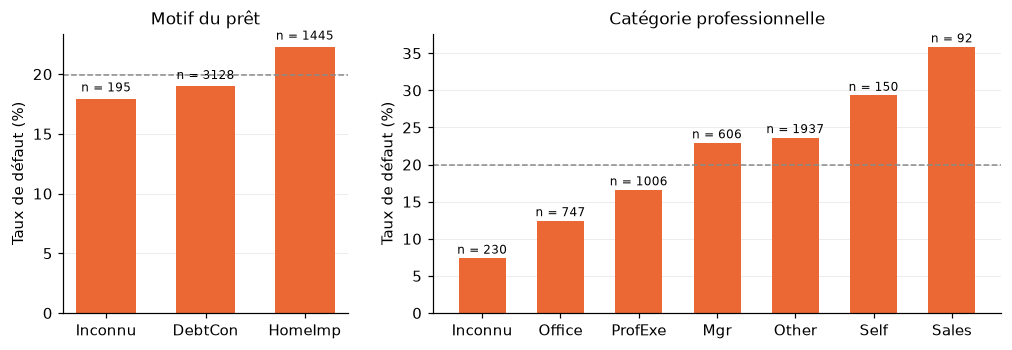

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 2]})
for ax, c in zip(axes, CAT_COLS):
    t = dev.assign(**{c: dev[c].fillna("Inconnu")}).groupby(c)[TARGET].agg(["mean", "size"]).sort_values("mean")
    bars = ax.bar(t.index, 100 * t["mean"], color=C_BAD, width=0.6)
    for b, n in zip(bars, t["size"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"n = {n}", ha="center", fontsize=8)
    ax.axhline(100 * dev[TARGET].mean(), color=GREY, ls="--", lw=1)
    ax.set_title(LABELS[c]); ax.set_ylabel("Taux de défaut (%)"); ax.grid(axis="x", visible=False)
    display(t.assign(mean=(100 * t["mean"]).round(1)).rename(columns={"mean": "taux de défaut (%)", "size": "effectif"}))
fig.savefig(FIG_DIR / "eda_categorielles.png"); plt.show()

## 6. Valeurs extrêmes

In [7]:
q1, q3 = dev[NUM_COLS].quantile(0.25), dev[NUM_COLS].quantile(0.75)
iqr = q3 - q1
is_out = (dev[NUM_COLS] < q1 - 3 * iqr) | (dev[NUM_COLS] > q3 + 3 * iqr)
out = pd.DataFrame({"% hors [Q1 - 3 IQR, Q3 + 3 IQR]": 100 * is_out.mean(),
                    "taux de défaut parmi ces valeurs (%)": [100 * dev.loc[is_out[c], TARGET].mean() for c in NUM_COLS],
                    "maximum": dev[NUM_COLS].max(), "99e centile": dev[NUM_COLS].quantile(0.99)}).round(1)
display(out.sort_values("% hors [Q1 - 3 IQR, Q3 + 3 IQR]", ascending=False))
print("Asymétrie (skewness) des montants :", dev[["LOAN", "MORTDUE", "VALUE"]].skew().round(2).to_dict(),
      "| après logarithme :", np.log1p(dev[["LOAN", "MORTDUE", "VALUE"]]).skew().round(2).to_dict())

,"% hors [Q1 - 3 IQR, Q3 + 3 IQR]",taux de défaut parmi ces valeurs (%),maximum,99e centile
DELINQ,20.3,44.3,15.0,5.0
DEROG,12.2,48.3,10.0,4.0
VALUE,1.4,17.9,855909.0,289944.2
MORTDUE,1.1,13.7,399550.0,232578.4
LOAN,1.0,10.9,89900.0,60000.0
NINQ,0.9,44.4,17.0,9.0
CLAGE,0.3,12.5,1168.2,399.2
CLNO,0.2,100.0,71.0,51.0
DEBTINC,0.2,100.0,203.3,49.1
YOJ,0.0,NaN,41.0,30.0


Asymétrie (skewness) des montants : {'LOAN': 2.05, 'MORTDUE': 1.81, 'VALUE': 2.99} | après logarithme : {'LOAN': -0.29, 'MORTDUE': -0.85, 'VALUE': -0.09}


## 7. Corrélations

Entre variables, puis séparément parmi les bons payeurs et parmi les défauts : c'est la structure que les générateurs de défauts synthétiques devront reproduire.

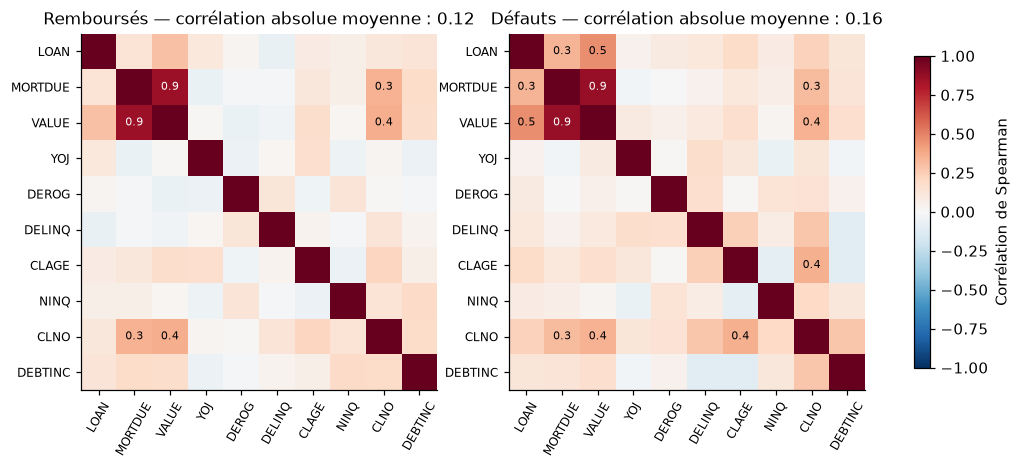

Corrélation MORTDUE / VALUE : 0.86


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, d, title in [(axes[0], good, "Remboursés"), (axes[1], bad, "Défauts")]:
    corr = d[NUM_COLS].corr("spearman")
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(NUM_COLS))); ax.set_xticklabels(NUM_COLS, rotation=60, fontsize=8)
    ax.set_yticks(range(len(NUM_COLS))); ax.set_yticklabels(NUM_COLS, fontsize=8); ax.grid(False)
    for i in range(len(NUM_COLS)):
        for j in range(len(NUM_COLS)):
            if i != j and abs(corr.values[i, j]) >= 0.3:
                ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(corr.values[i, j]) > 0.6 else "black")
    off = np.abs(corr.values[np.triu_indices(len(NUM_COLS), k=1)])
    ax.set_title(f"{title} — corrélation absolue moyenne : {off.mean():.2f}")
fig.colorbar(im, ax=axes, shrink=0.8, label="Corrélation de Spearman")
fig.savefig(FIG_DIR / "eda_correlations.png"); plt.show()
print("Corrélation MORTDUE / VALUE :", round(dev[["MORTDUE", "VALUE"]].corr("spearman").iloc[0, 1], 2))

## 8. Ce que l'exploration impose à la suite du projet

| Constat | Conséquence pour la modélisation |
|---|---|
| 19,9 % de défauts : déséquilibre réel mais modéré | Métrique principale : PR-AUC (avec ROC-AUC et KS, usuels en scoring). Une étude de rareté réduit artificiellement le nombre de défauts d'entraînement pour tester les méthodes sous fort déséquilibre. |
| Seules 56 % des lignes sont complètes | Supprimer les lignes incomplètes ferait perdre près de la moitié des données : on impute (médiane apprise sur l'entraînement). |
| Les valeurs manquantes sont informatives : 62 % de défauts quand le ratio dette / revenu manque, contre 9 % sinon | Un indicateur « valeur manquante » par variable est ajouté. Les générateurs doivent eux aussi reproduire les valeurs manquantes. |
| Montants très asymétriques (asymétrie 2 à 3, ramenée près de 0 par le logarithme) | Transformation log(1 + x) des montants ; ajout du ratio d'endettement sur le bien (LTV). |
| Retards et incidents : variables de comptage, très concentrées en 0, très discriminantes | Les générateurs doivent produire des entiers ; une interpolation naïve (SMOTE) crée des valeurs non entières, d'où SMOTE-NC et un arrondi. |
| Deux variables catégorielles (motif, profession) | Encodage one-hot ; SMOTE-NC plutôt que SMOTE ; générateurs capables de traiter des données mixtes. |
| MORTDUE et VALUE fortement corrélées (0,86) | Un bon générateur doit reproduire cette dépendance : c'est l'un des critères de qualité mesurés. |

Toutes ces statistiques sont calculées sur le jeu de développement : le jeu de test n'a pas été regardé.